# EDA Альфа-Банка

## Таблица признаков

| Признак | Что означает |
|---|---|
| `id` | Идентификатор клиента |
| `rn` | Номер кредита в истории клиента |
| `pre_since_opened` | Давность открытия кредита |
| `pre_since_confirmed` | Давность подтверждения данных |
| `pre_pterm`, `pre_fterm` | Плановый и фактический срок кредита |
| `pre_till_pclose`, `pre_till_fclose` | Время до планового и фактического закрытия |
| `pre_loans_credit_limit` | Кредитный лимит |
| `pre_loans_next_pay_summ` | Следующий платеж |
| `pre_loans_outstanding` | Остаток долга |
| `pre_loans_total_overdue` | Текущая просрочка |
| `pre_loans_max_overdue_sum` | Максимальная просрочка |
| `pre_loans_credit_cost_rate` | Стоимость кредита |
| `pre_loans5` ... `pre_loans90` | Просрочки разной длительности |
| `is_zero_loans5` ... `is_zero_loans90` | Флаги отсутствия просрочек |
| `pre_util` | Использование кредитного лимита |
| `pre_over2limit`, `pre_maxover2limit` | Просрочка относительно лимита |
| `is_zero_util`, `is_zero_over2limit`, `is_zero_maxover2limit` | Флаги отсутствия долга или просрочки |
| `enc_paym_0` ... `enc_paym_24` | Платежные статусы за 25 месяцев |
| `enc_loans_account_holder_type` | Тип отношения к кредиту |
| `enc_loans_credit_status` | Статус кредита |
| `enc_loans_account_cur` | Валюта кредита |
| `enc_loans_credit_type` | Тип кредита |
| `pclose_flag`, `fclose_flag` | Флаги неизвестной даты закрытия |
| `flag` | Целевая переменная: 1 — дефолт, 0 — нет |


## Импорт и загрузка данных

In [1]:
# Подключение библиотек для таблиц и графиков.
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

# Указание папки с данными и чтение целевой переменной.
DATA_PATH = Path('data_for_competition')
target = pd.read_csv(DATA_PATH / 'train_target.csv')
files = sorted((DATA_PATH / 'train_data').glob('*.pq'))

# Для графиков используется небольшая часть каждого файла: полный датасет слишком большой.
parts = []
for file in files:
    part = pd.read_parquet(file)
    parts.append(part.sample(min(10_000, len(part)), random_state=RANDOM_STATE))

# Объединение кредитной истории с информацией о дефолте.
df = pd.concat(parts, ignore_index=True).merge(target, on='id', how='left')
X = df.drop(columns='flag')

print('Размер выборки:', df.shape)
print('Размер полного файла с таргетом:', target.shape)

Размер выборки: (120000, 62)
Размер полного файла с таргетом: (3000000, 2)


## Основная информация

In [2]:
# Просмотр первых строк и основных статистик по всем признакам.
display(df.head())
display(df.describe(include='all').T)

,id,rn,pre_since_opened,pre_since_confirmed,pre_pterm,pre_fterm,pre_till_pclose,pre_till_fclose,pre_loans_credit_limit,pre_loans_next_pay_summ,...,enc_paym_22,enc_paym_23,enc_paym_24,enc_loans_account_holder_type,enc_loans_credit_status,enc_loans_credit_type,enc_loans_account_cur,pclose_flag,fclose_flag,flag
0,158299,2,0,17,8,11,6,3,5,2,...,3,3,4,1,3,1,1,0,0,0
1,31000,3,8,7,8,11,9,1,6,2,...,3,3,4,1,3,4,1,0,0,0
2,64097,6,4,17,4,8,1,11,4,2,...,3,3,4,1,3,3,1,1,1,0
3,88521,3,8,9,16,9,9,1,5,6,...,3,3,4,1,3,4,1,0,0,0
4,242052,1,11,10,0,8,10,11,11,3,...,3,3,4,1,2,3,1,0,1,0


,count,mean,std,min,25%,50%,75%,max
id,120000.0,1.500318e+06,865176.480743,6.0,749996.0,1500006.5,2249968.5,2999972.0
rn,120000.0,7.026275e+00,5.387997,1.0,3.0,6.0,10.0,40.0
pre_since_opened,120000.0,9.359283e+00,5.777952,0.0,4.0,9.0,14.0,19.0
pre_since_confirmed,120000.0,8.203867e+00,4.710330,0.0,4.0,9.0,11.0,17.0
pre_pterm,120000.0,8.373358e+00,5.336714,0.0,4.0,8.0,14.0,17.0
...,...,...,...,...,...,...,...,...
enc_loans_credit_type,120000.0,3.512175e+00,1.035717,0.0,3.0,4.0,4.0,7.0
enc_loans_account_cur,120000.0,1.001750e+00,0.049970,0.0,1.0,1.0,1.0,2.0
pclose_flag,120000.0,1.487833e-01,0.355876,0.0,0.0,0.0,0.0,1.0
fclose_flag,120000.0,2.308917e-01,0.421405,0.0,0.0,0.0,0.0,1.0


## Пропуски

In [3]:
# Подсчет количества и доли пропусков в каждом признаке.
missing = pd.DataFrame({
    'пропусков': X.isna().sum(),
    'доля, %': (X.isna().mean() * 100).round(3)
})
display(missing)
print('Всего пропусков:', X.isna().sum().sum())

,пропусков,"доля, %"
id,0,0.0
rn,0,0.0
pre_since_opened,0,0.0
pre_since_confirmed,0,0.0
pre_pterm,0,0.0
...,...,...
enc_loans_credit_status,0,0.0
enc_loans_credit_type,0,0.0
enc_loans_account_cur,0,0.0
pclose_flag,0,0.0


Всего пропусков: 0


## Ящики с усами

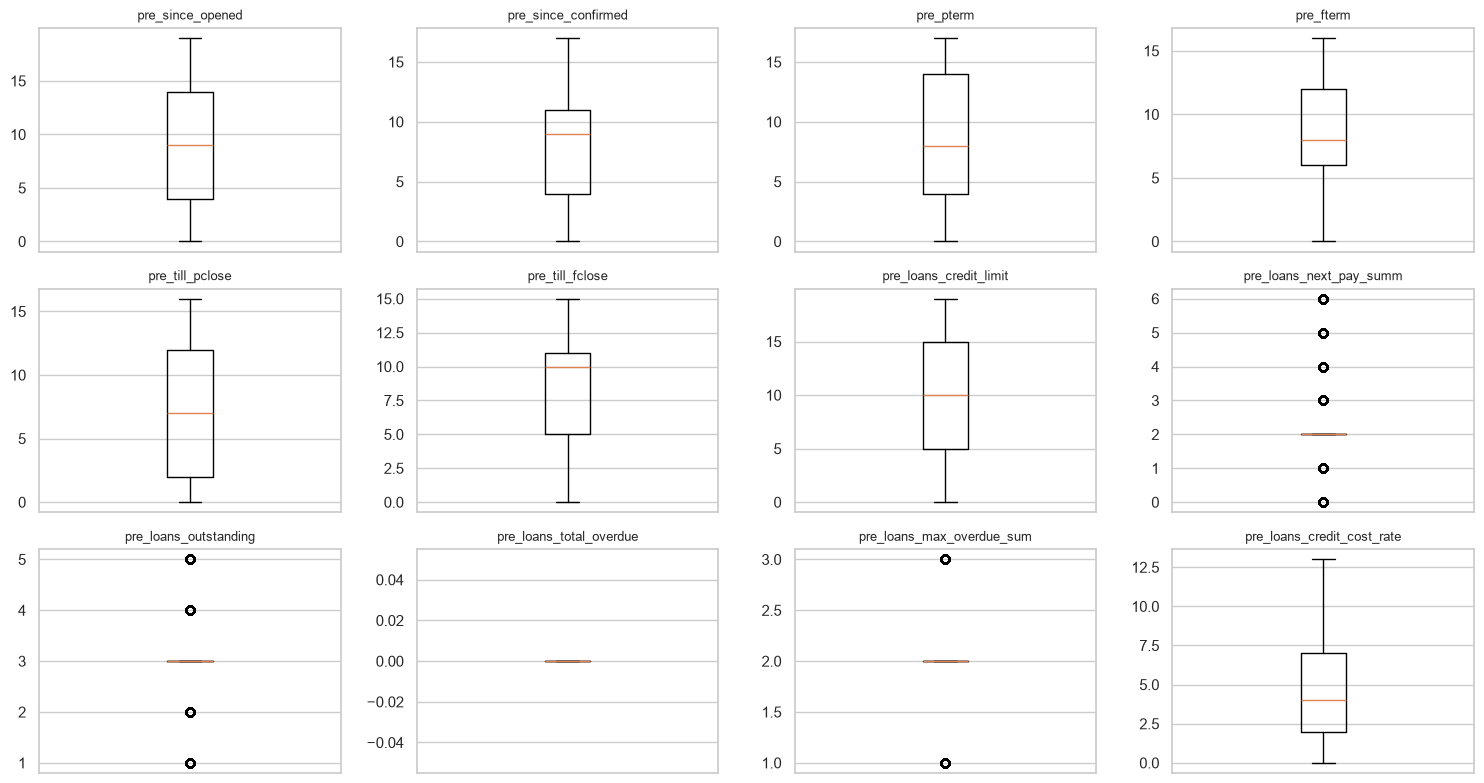

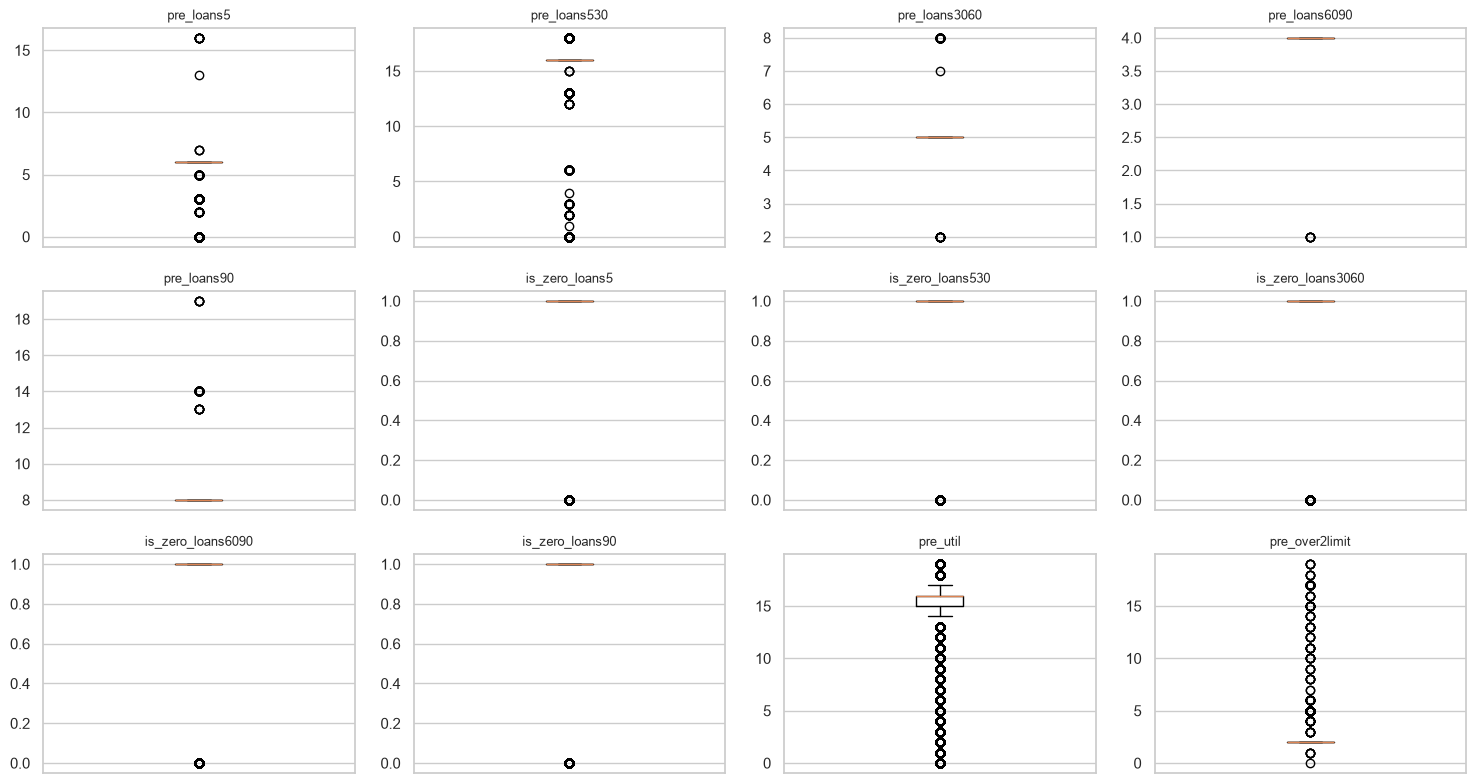

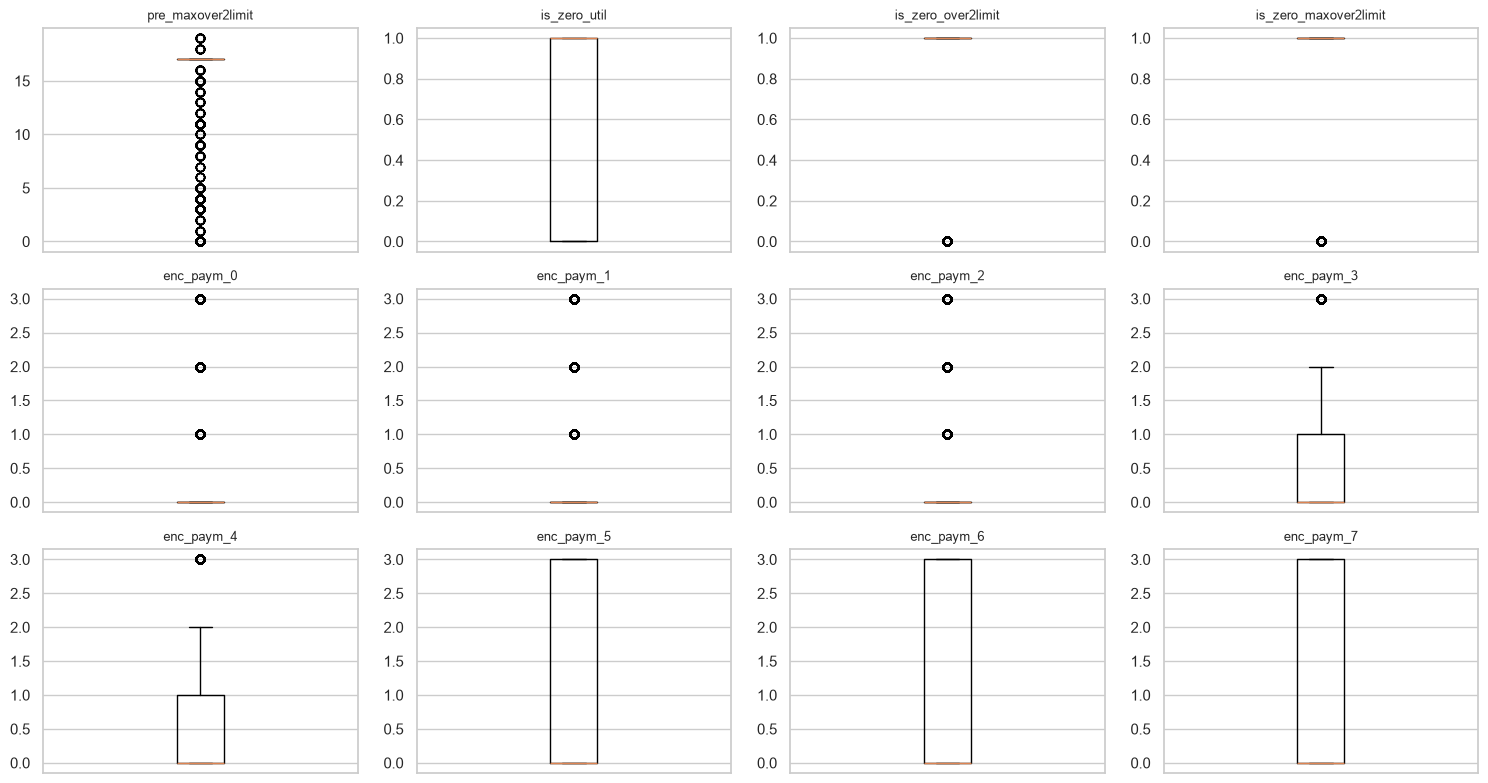

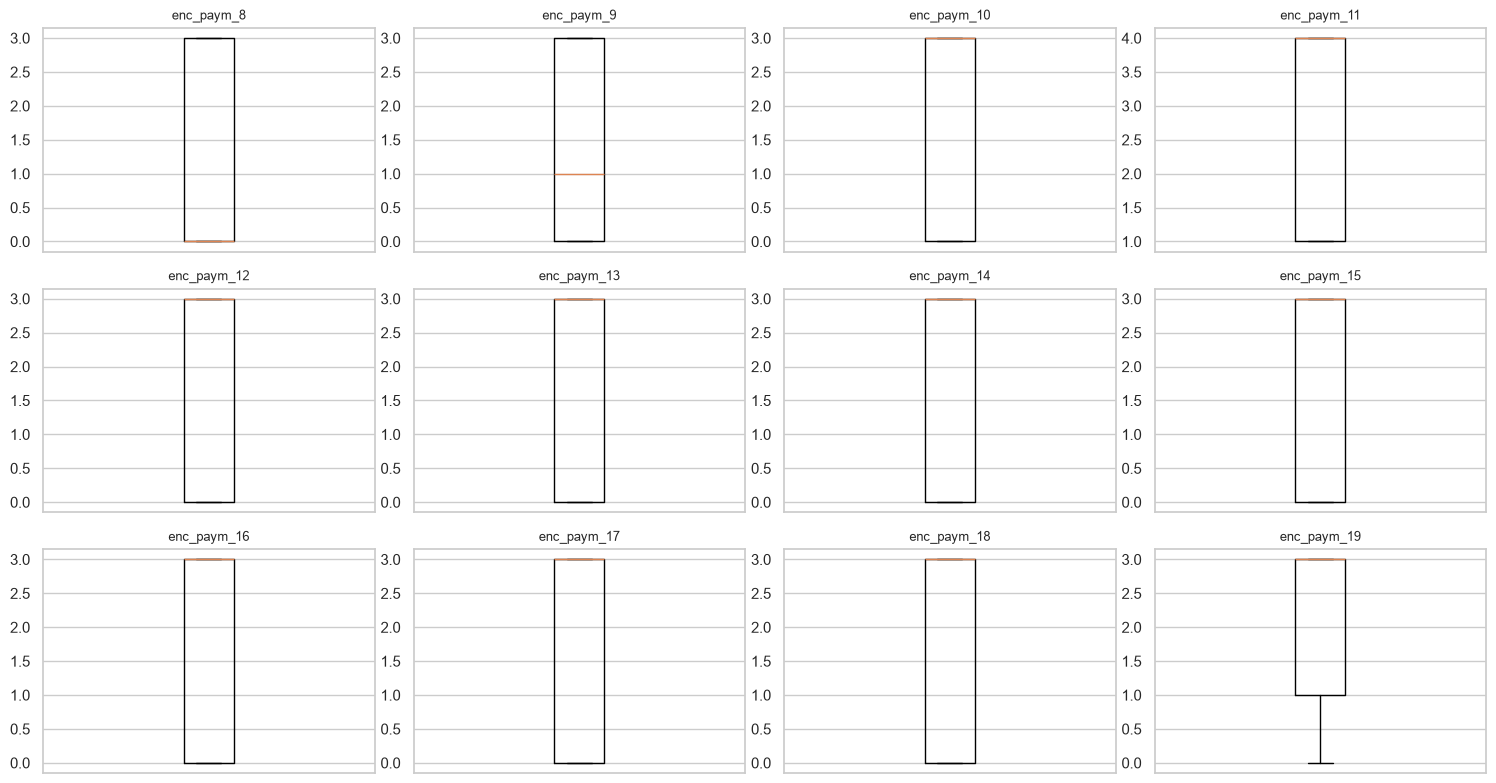

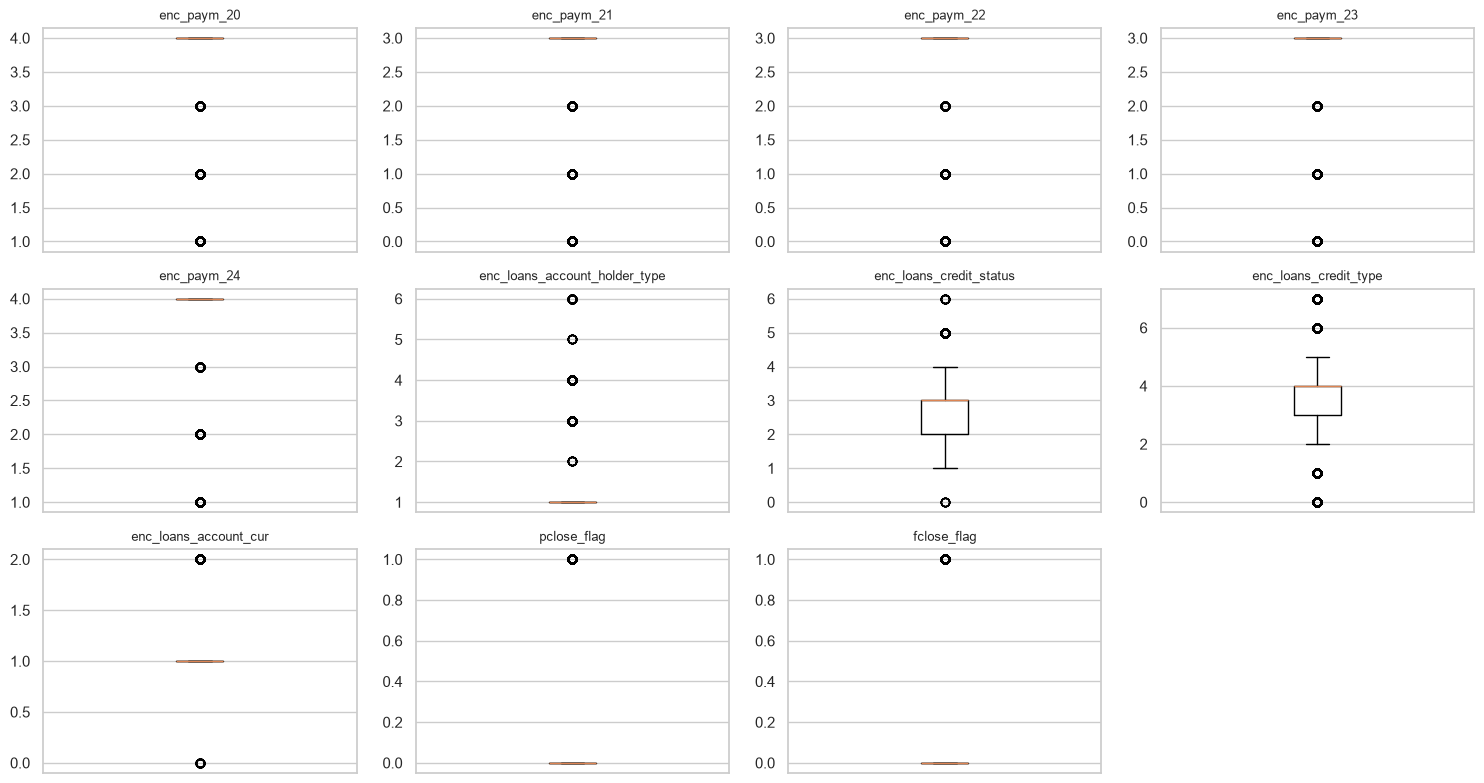

In [4]:
# Построение ящиков с усами для всех признаков, кроме технических id и rn.
boxplot_columns = [column for column in X.columns if column not in ['id', 'rn']]

for start in range(0, len(boxplot_columns), 12):
    columns_part = boxplot_columns[start:start + 12]
    fig, axes = plt.subplots(3, 4, figsize=(15, 8))
    for ax, column in zip(axes.flat, columns_part):
        ax.boxplot(df[column])
        ax.set_title(column, fontsize=9)
        ax.set_xticks([])
    for ax in axes.flat[len(columns_part):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

## Матрица корреляций

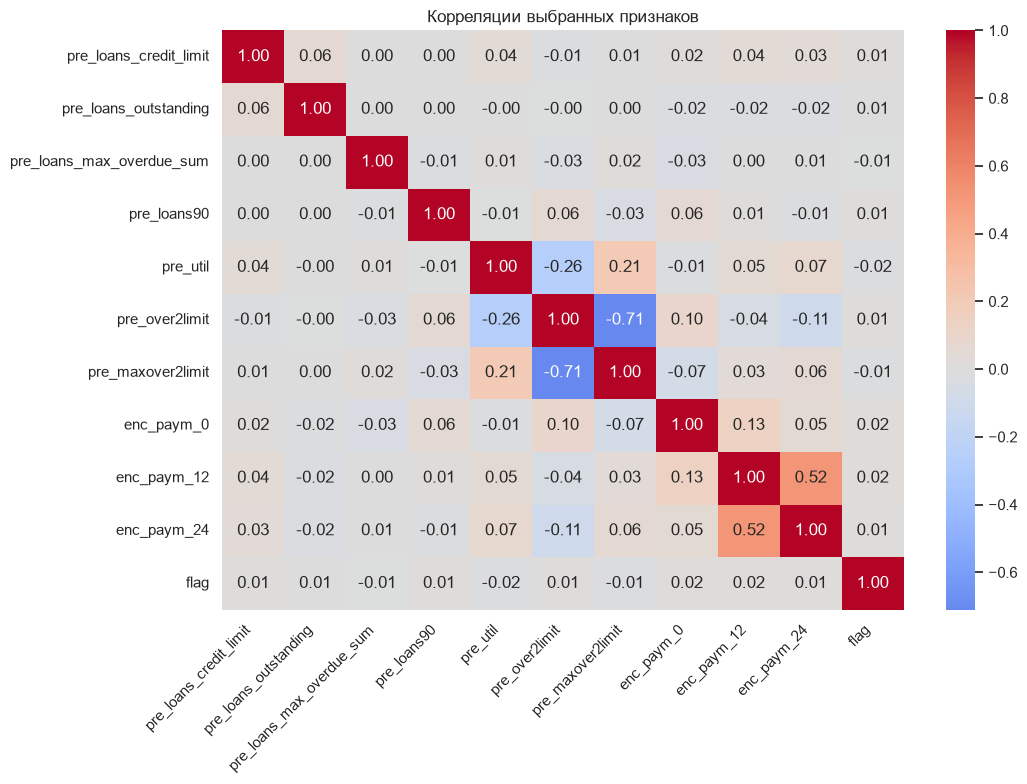

In [5]:
# Выбор понятных и часто встречающихся признаков для читаемой матрицы.
columns = [
    'pre_loans_credit_limit', 'pre_loans_outstanding',
    'pre_loans_max_overdue_sum', 'pre_loans90', 'pre_util',
    'pre_over2limit', 'pre_maxover2limit',
    'enc_paym_0', 'enc_paym_12', 'enc_paym_24', 'flag'
]
columns = [column for column in columns if df[column].nunique() > 1]

plt.figure(figsize=(11, 8))
sns.heatmap(df[columns].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляции выбранных признаков')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Короткие выводы

В датасете очень большой объем данных: один клиент может иметь несколько кредитов, а для каждого кредита есть платежные статусы за разные месяцы. Поэтому эти данные можно рассматривать как кредитную историю клиента во времени. Для графиков использована выборка, чтобы ноутбук работал быстро. В дальнейшем данные по нескольким кредитам нужно будет агрегировать в одну строку на клиента и затем строить модель прогнозирования дефолта.